[All milestones](../START_HERE.ipynb) · [Main solution](../solution/reduced_qubit_hybrid_hourly.ipynb)

# Milestone 3 — hourly QUBO and QAOA

Completed cost coefficients, capacity/slack penalty, Ising encoding, exact hourly check, and QAOA circuit. See the completed [Max-Cut primer](03_max_cut_primer.ipynb). Both encode binary choices in a cost Hamiltonian; this model adds plant costs and a reserve penalty.

The 24 hourly matches below are conditional on the MILP previous-hour states, not a proof of full-day optimality.

In [1]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


In [2]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no remote job. Select an environment that already includes it.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    raise ImportError("Use a qBraid environment with qiskit-aer installed.")

import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


MILP solved in 0.065 s
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


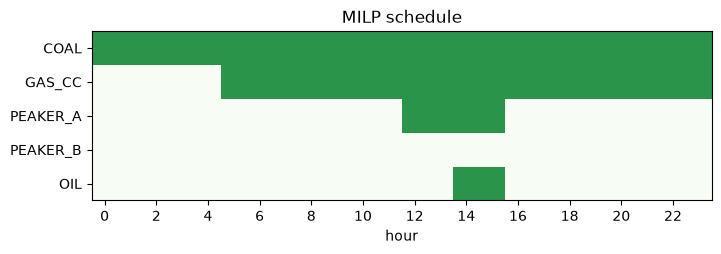

In [3]:
milp_cost, milp_schedule, milp_dispatch, secs = solve_milp(plants, demand, reserve)
print(f"MILP solved in {secs:.3f} s")
milp_result = check_schedule(plants, demand, reserve, milp_schedule, milp_cost=milp_cost)


def plot_schedule(schedule, title, ax=None):
    # Green = on. One row per plant, one column per hour.
    if ax is None:
        ax = plt.subplots(figsize=(8, 2.2))[1]
    ax.imshow(np.asarray(schedule).T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(N), names)
    ax.set_xticks(range(0, len(demand), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    return ax


plot_schedule(milp_schedule, "MILP schedule")
plt.show()

## 3. One hour as a QUBO (Milestone 3)

The completed six-node [QAOA primer](03_max_cut_primer.ipynb) explains the cost layer, mixer and classical angle optimizer used here.

**QUBO** (quadratic unconstrained binary optimization): a cost function over 0/1 variables that has only single terms and pair terms. The QAOA code in this notebook takes the problem in this form.

One hour uses 8 qubits:

| Qubits | Meaning |
|---|---|
| 0 to 4 | $x_i = 1$ if plant $i$ is on (COAL, GAS_CC, PEAKER_A, PEAKER_B, OIL) |
| 5 to 7 | helper (slack) bits $s_0, s_1, s_2$ for the safety-margin rule |

QAOA should find the bits with the lowest energy

$$E = \sum_i c_i x_i + A \Big(\sum_i a_i x_i - (s_0 + 2 s_1 + 4 s_2) - r\Big)^2$$

- $c_i$ is the cost of having plant $i$ on this hour (hourly cost coefficients).
- The rule is "capacity of the plants that are on ≥ demand + reserve". We count capacity in 50 MW blocks: plant $i$ is $a_i = \text{pmax}_i / 50$ blocks (COAL and GAS_CC are 7, the small plants are 1), and the hour needs $r = \lceil (\text{demand} + \text{reserve}) / 50 \rceil$ blocks.
- A QUBO cannot say "≥". So the slack bits spell out the spare blocks in binary: spare $= s_0 + 2 s_1 + 4 s_2$, from 0 to 7. If the plants have enough capacity, with at most 7 spare blocks, one slack setting makes the bracket exactly 0 and the penalty vanishes. If they are short, no slack setting helps and the penalty is at least $A$.
- Three slack bits cover 0 to 7 spare blocks (up to 350 MW). That is enough for the best choice in every hour of this day. Two things this QUBO doesn't get right: a choice with more than 7 spare blocks is penalized even though it's allowed, and the rule "minimum outputs can't exceed demand" isn't in the QUBO at all. Find an hour and a choice for each. Which step in section 5 catches them?
- $A$ is the penalty weight. It must be bigger than what any plant saves by breaking the rule. We start with $A = 2 \max_i c_i$.

### Hourly plant commitment cost

$$c_i = \text{startup}_i \cdot (1 - \text{was\_on}_i) + \text{no\_load}_i + \text{pmin}_i \cdot (\text{marginal}_i - \text{marginal}_\text{cheapest})$$

Why: a plant that is on must make at least pmin MW. The rest of the demand comes from the cheapest plant with room to spare (COAL, whenever it has room), whichever plants you pick. So what plant $i$ adds is its startup (only if it was off last hour), its no-load cost, and its extra price on those pmin MW.

This is an approximation. It ignores who makes the last MW when COAL is already full. The checker uses the exact cost, so you can measure how often this picks the true best. Try a few demand levels and previous on/off states. (Improving it is a stretch goal.)

`was_on[i]` is 1 if plant `i` was on in the previous hour. `marginal_cheapest` is the smallest `marginal_cost_per_mwh` in the fleet.

In [4]:
def plant_hour_costs(plants, was_on):
    c = np.zeros(len(plants))

    marginal_cheapest = min(
        p["marginal_cost_per_mwh"] for p in plants
    )

    for i, p in enumerate(plants):
        startup = p["startup_cost"] * (1 - was_on[i])
        no_load = p["no_load_cost_per_h"]
        extra_energy = p["pmin_mw"] * (
            p["marginal_cost_per_mwh"] - marginal_cheapest
        )

        c[i] = startup + no_load + extra_energy

    return c

### QUBO matrix

Store the QUBO as an 8 × 8 matrix `Q` and a number `offset`:

$$\text{energy}(y) = \sum_j Q[j, j]\, y_j + \sum_{j<k} Q[j, k]\, y_j y_k + \text{offset}$$

The diagonal holds single terms, the upper triangle holds pair terms, the lower triangle is unused.

Hint: put all 8 bits in one list $y = (x_0, \dots, x_4, s_0, s_1, s_2)$ with weights $b = (a_0, \dots, a_4, -1, -2, -4)$. The bracket is then $\sum_j b_j y_j - r$. Because $y_j^2 = y_j$ for 0/1 bits,

$$\Big(\sum_j b_j y_j - r\Big)^2 = \sum_j (b_j^2 - 2 r b_j)\, y_j + \sum_{j<k} 2 b_j b_k\, y_j y_k + r^2$$

1. Cost part: add `c[i]` to `Q[i, i]` for each plant.
2. Penalty part: multiply each term of the expansion by `A` and add it to the right place: single terms on the diagonal, pair terms at `Q[j, k]` with `j < k`, the constant to `offset`.

`b` and `r` are computed for you.

In [5]:
BLOCK_MW = 50
N_SLACK = 3
N_QUBITS = N + N_SLACK


def build_qubo(plants, demand_mw, reserve_mw, was_on, penalty=None):
    c = plant_hour_costs(plants, was_on)
    A = 2 * c.max() if penalty is None else penalty

    # Plant capacity weights, followed by negative slack weights.
    b = np.array(
        [p["pmax_mw"] / BLOCK_MW for p in plants]
        + [-(2 ** k) for k in range(N_SLACK)]
    )

    # Required capacity in 50 MW blocks.
    r = np.ceil((demand_mw + reserve_mw) / BLOCK_MW)

    Q = np.zeros((N_QUBITS, N_QUBITS))
    offset = 0.0

    # Approximate operating costs.
    for i in range(len(plants)):
        Q[i, i] += c[i]

    # Capacity penalty: A * (sum(b[j] * y[j]) - r)**2.
    for j in range(N_QUBITS):
        Q[j, j] += A * (b[j] ** 2 - 2 * r * b[j])

        for k in range(j + 1, N_QUBITS):
            Q[j, k] += 2 * A * b[j] * b[k]

    offset += A * r ** 2

    return Q, offset

In [6]:
# Bit j of an integer index = qubit j. Row k of INDEX_BITS holds the 8 bits of index k.
# (Qiskit prints bitstrings with qubit 0 as the LAST character. Using integer indices
#  everywhere means you never have to reverse a string.)
INDEX_BITS = (np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1
PLANT_INDEX = INDEX_BITS[:, :N] @ (2 ** np.arange(N))   # on/off choice (0..31) inside each index


def all_energies(Q, offset):
    # QUBO energy of every bitstring in the configured state table.
    U = np.triu(Q)
    return np.einsum("bj,jk,bk->b", INDEX_BITS, U, INDEX_BITS) + offset


def brute_force_qubo(Q, offset):
    E = all_energies(Q, offset)
    k = int(np.argmin(E))
    return INDEX_BITS[k], E[k]


def label(choice):
    # Plant names for an on/off choice given as a 0..31 index or a list of 0/1.
    on = [(choice >> i) & 1 for i in range(N)] if np.isscalar(choice) else choice
    return "+".join(n for n, u in zip(names, on) if u) or "none"

### Check your QUBO

The brute force tries all 256 bitstrings of your QUBO and keeps the cheapest. `check_hour` compares its plant bits with the best of all 32 on/off choices, using the exact cost. **Milestone 3 is done when it prints "Match!"** That checks one hour, given the hour before; it doesn't prove a good full day.

Compare the best choice for this hour with what the MILP picked for it. If they differ, which one is right, and why?

In [7]:
TEST_HOUR = 12
was_on = milp_schedule[TEST_HOUR - 1]        # who was on the hour before (from the MILP)
Q, offset = build_qubo(plants, demand[TEST_HOUR], reserve[TEST_HOUR], was_on)
bits, energy = brute_force_qubo(Q, offset)
print(f"Cheapest QUBO bitstring: plants {bits[:N]}, slack {bits[N:]}, energy {energy:,.0f}")
check_hour(plants, demand[TEST_HOUR], reserve[TEST_HOUR], bits[:N], was_on=was_on)
print("(The MILP picked", label(list(milp_schedule[TEST_HOUR])), "for this hour.)")

Cheapest QUBO bitstring: plants [1 1 0 0 1], slack [0 0 0], energy 4,028
Your choice: COAL+GAS_CC+OIL  ->  valid, cost $18,810
Match!
(The MILP picked COAL+GAS_CC+PEAKER_A for this hour.)


In [8]:
# Every hour at once, with the MILP's previous hour as "who was on".
start_state = [int(p["on_at_start"]) for p in plants]
matches = 0
for t in hours:
    was = milp_schedule[t - 1] if t > 0 else start_state
    Qt, off_t = build_qubo(plants, demand[t], reserve[t], was)
    bits_t, _ = brute_force_qubo(Qt, off_t)
    matches += check_hour(plants, demand[t], reserve[t], bits_t[:N], was_on=was, verbose=False)["matches_best"]
print(f"Your QUBO's cheapest answer matches the brute-force best in {matches} of {len(hours)} hours.")


print("Our per-hour solution uses oil rather than PEAKER_A because oil is cheaper to start but expensive to continue running, while PEAKER_A is expensive to start but cheaper to keep running. This explains why a per-hour solution will use oil rather than PEAKER_A")

Your QUBO's cheapest answer matches the brute-force best in 24 of 24 hours.
Our per-hour solution uses oil rather than PEAKER_A because oil is cheaper to start but expensive to continue running, while PEAKER_A is expensive to start but cheaper to keep running. This explains why a per-hour solution will use oil rather than PEAKER_A


## 4. QAOA for one hour

These helpers are provided:

1. `qubo_to_ising` replaces each bit $y$ with $(1 - z)/2$, which gives single-qubit $Z$ terms and $ZZ$ pair terms.
2. `qaoa_circuit` builds `p` layers: an `rz` on each qubit and an `rzz` on each pair (the cost layer), then an `rx` on each qubit (the mixer).
3. `run_qaoa` tunes the angles with COBYLA, using the exact statevector (fast for 8 qubits). It minimizes the average energy, rescaled to the range 0 to 1.
4. `choice_probs` adds up the probability over the slack qubits, giving the chance of each of the 32 on/off choices.

Be clear about this in your story: to tune the angles, `run_qaoa` scores all 256 bitstrings first, which already finds the best one, and the loop below checks all 32 choices for its report. Count that classical work in your timing.

In [9]:
def qubo_to_ising(Q):
    # y = (1 - z) / 2 turns the QUBO into  sum_j h_j Z_j + sum_jk J_jk Z_j Z_k + constant.
    h, J = np.zeros(len(Q)), {}
    for j in range(len(Q)):
        h[j] -= Q[j, j] / 2
        for k in range(j + 1, len(Q)):
            if Q[j, k] != 0:
                J[(j, k)] = Q[j, k] / 4
                h[j] -= Q[j, k] / 4
                h[k] -= Q[j, k] / 4
    return h, J


def qaoa_circuit(Q, p=1):
    # Parameterized QAOA circuit with p layers. Returns (circuit, parameters).
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))   # keeps angles in a sane range
    gammas, betas = ParameterVector("gamma", p), ParameterVector("beta", p)
    qc = QuantumCircuit(len(Q))
    qc.h(range(len(Q)))
    for layer in range(p):
        for j, hj in enumerate(h):
            if hj != 0:
                qc.rz(2 * gammas[layer] * hj / scale, j)
        for (j, k), Jjk in J.items():
            qc.rzz(2 * gammas[layer] * Jjk / scale, j, k)
        qc.rx(2 * betas[layer], range(len(Q)))
    return qc, list(gammas) + list(betas)


def run_qaoa(Q, offset, p=1, start=None, maxiter=60):
    # Tune angles on the exact statevector; return angles and basis-state probabilities.
    E = all_energies(Q, offset)
    E = (E - E.min()) / (E.max() - E.min())
    qc, params = qaoa_circuit(Q, p)

    def probs_at(angles):
        return Statevector(qc.assign_parameters(dict(zip(params, angles)))).probabilities()

    def average_energy(angles):
        return probs_at(angles) @ E

    if start is None or len(start) != 2 * p:     # coarse grid for one (gamma, beta), used in every layer
        grid = [(g, b) for g in np.linspace(0.1, 3.0, 15) for b in np.linspace(0.1, 1.5, 8)]
        g, b = min(grid, key=lambda gb: average_energy([gb[0]] * p + [gb[1]] * p))
        start = [g] * p + [b] * p
    result = minimize(average_energy, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, probs_at(result.x)


def choice_probs(probs):
    # Plant on/off probabilities, marginalized over the slack qubits.
    return np.bincount(PLANT_INDEX, weights=probs, minlength=2 ** N)

QAOA for hour 12: 0.47 s, angles [ 0.638 -0.655]


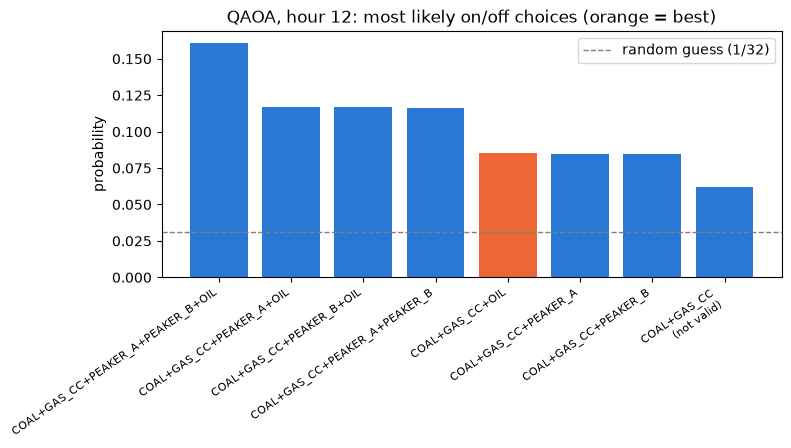

P(best choice) = 0.085   random guess = 0.031


In [10]:
start = time.perf_counter()
angles, probs = run_qaoa(Q, offset, p=1)
print(f"QAOA for hour {TEST_HOUR}: {time.perf_counter() - start:.2f} s, angles {np.round(angles, 3)}")

pc = choice_probs(probs)
best_k = int(bits[:N] @ (2 ** np.arange(N)))          # brute-force best from above
top = np.argsort(-pc)[:8]
valid = [hour_ok(plants, demand[TEST_HOUR], reserve[TEST_HOUR], [(k >> i) & 1 for i in range(N)]) for k in top]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(top)), pc[top], color=[COLORS["qaoa"] if k == best_k else COLORS["milp"] for k in top])
ax.axhline(1 / 2 ** N, color="gray", ls="--", lw=1, label="random guess (1/32)")
ax.set_xticks(range(len(top)), [label(int(k)) + ("" if ok else "\n(not valid)") for k, ok in zip(top, valid)],
              rotation=35, ha="right", fontsize=8)
ax.set(ylabel="probability", title=f"QAOA, hour {TEST_HOUR}: most likely on/off choices (orange = best)")
ax.legend()
plt.show()
print(f"P(best choice) = {pc[best_k]:.3f}   random guess = {1 / 2 ** N:.3f}")